### Overview
- We have already tried a handful of ML pipelines to build a predictor for venetoclax sensitivity from RNAseq data
- While some samples can be classified more easily as sensitive or resistant, stability of predictions between changes (with feature selection, model type, order of pipeline steps) has always been an issue and many samples have relatively weak predicted probabilities (close to 50%)
- One observation from trying to fit a regressor to predict venetoclax AUC from RNAseq counts is that r^2 is very low - usually close to zero. This means that among the cohort, the gene expression only models a tiny bit of the variance. 
    - This could be explained by gene expression not modeling venetoclax response but I find that doubtful because the ratio of BCL2 to MCL1 (or BCL2L1) has been thought of as a biomarker for venetoclax sensitivity 
    - What could be that among the cohort there are patients whose drug response is driven by more than just gene expression, they could also have copy number alterations of BCL2 family proteins or indels

#### Goals
- The goal of this notebook is to compare samples with high predicted probabilities to samples with low predicted probabilities
- After predictions we split into low and high probability cohorts, and compare inter-cohort predicted sensitive and resistant patients to see:
    - Is there a significant difference in continuous venetoclax AUC?
    - What are the transcriptomic and pathway level differences?
    - What genes are driving predictions, does it make sense (sequencing artifact vs. response related biology)?
        - SHAP analysis
    - Using OLS workflow, do predicted probabilities within this cohort complement t(11;14) in predicting venetoclax sensitivity?
    - Are there significant differences in mutation states between predicted sensitive vs. resistant within this probability cohort
        - Indels
        - copy-number alterations if availiable 
    - Using a simple barplot, between sensitive and resistant what stands out with their clinical metadata
        - i.e. multiple myeloma stage, number of previous treatments, tumor purity of the sample if it is availiable
- Response groups will be defined before cross-validation within the moffitt cohort 
    - Use 4-fold CV because the model will train of 75% of the data before predicted - increased stability of predictions

#### Steps

1. Label samples as sensitive, resistant (and moderate)
1. Run cross validation and predict on sensitive and resistant patients only
2. Get metrics with CIs
3. Train the full model (SCALE THE TRAINING DATA FIRST), and predict probability of sensitivity of patients labelled as moderate
3. Using a predicted probability threshold, split samples into high and low probability cohorts. **>=75 will be considered high confidence**
    3a. Show histogram of predicted probabilities of the dataset, then for both probabilty cohorts indivudally
4. Within each probability cohorts, using the OLS workflow, see if model probabilities are complementary to t(11;14) in predicting sensitivity 
5. Within each probability cohorts, compare:
    5a. differential expression and pathways
    5b. WES mutation differences - Indels (and copy number if availiable)



In [168]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns


from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score, accuracy_score
from sklearn.utils import resample

from scipy.stats import ttest_ind

from datasets.Harmonized_Datasets import harmonize

import pylimma 
import decoupler as dc
import gseapy as gp

import starbars



In [169]:
# CONSTANTS
PROBABILITY_CUTOFF = (0.25, 0.75) # inclusive
RANDOM_STATE=4 
N_SPLITS=4

In [170]:
# HELPER FUNCS
def cross_val_classification(X,y, model,n_splits=N_SPLITS, random_state=RANDOM_STATE, verbose=True):
   

    results = {"samples": [],
               "y_true": [],
               "y_pred": [],
               "y_prob": [],
               }

    fold_metrics = {
            "n_fold": [],
            "precision_score": [],
            "recall_score": [], 
            "f1_score": [],
  
            "accuracy": [],
            "roc_auc": [],
            }
     
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=random_state)
    n_fold= 0
    for i, (train_index, test_index) in enumerate(skf.split(X,y)):
        if verbose:
            print(f"CV FOLD: {n_fold + 1}")

        X_train, y_train = X.iloc[train_index], y.iloc[train_index]
        X_test, y_test = X.iloc[test_index], y.iloc[test_index]


        # add ground truth values
        results["y_true"] += list(y_test)
        
        # get test samples
        test_samples = X_test.index
        results["samples"] +=list(test_samples)
       
        # Scale the training data
        scl = StandardScaler()
        X_train = scl.fit_transform(X_train)
        X_test = scl.transform(X_test)
        
        # train model
        model.fit(X_train, y_train)

        # get fold predictions
        y_pred = model.predict(X_test)
        results["y_pred"] +=list(y_pred)

        # get fold probas
        y_prob = model.predict_proba(X_test)[:,1]
        results["y_prob"] +=list(y_prob)

        # record fold metrics
        n_fold +=1
        fold_metrics["n_fold"].append(n_fold)
        fold_metrics["precision_score"].append(precision_score(y_test, y_pred))
        fold_metrics["recall_score"].append(recall_score(y_test, y_pred))
        fold_metrics["f1_score"].append(f1_score(y_test, y_pred))
        fold_metrics["accuracy"].append(accuracy_score(y_test,y_pred))
        fold_metrics["roc_auc"].append(roc_auc_score(y_test, y_prob))

    if verbose:
        print(pd.DataFrame(fold_metrics))

   
    return results, fold_metrics

def get_bootstrap_metrics(results_df, alpha=0.05, bootstraps=10000, verbose=True):
    results_df = results_df.copy().set_index('samples')

    
    metric_statistics= {
        'accuracy': [],
        'precision': [],
        'recall': [],
        'f1': [],
        'roc_auc': []
    }
    bootstrap_results = {
        'accuracy': (),
        'precision': (),
        'recall': (),
        'f1': (),
        'roc_auc': (),
    }

    # get bootstrap statistics
    for i in range(bootstraps):
        res = resample(results_df)

        y_pred = res['y_pred']
        y_prob = res['y_prob']
        y_true = res['y_true']

        metric_statistics['accuracy'].append(accuracy_score(y_true, y_pred))
        metric_statistics['precision'].append(precision_score(y_true, y_pred))
        metric_statistics['recall'].append(recall_score(y_true, y_pred))
        metric_statistics['f1'].append(f1_score(y_true, y_pred))
        metric_statistics['roc_auc'].append(roc_auc_score(y_true, y_prob))

    # get confidence intervals
    for key in metric_statistics.keys():
        stat = metric_statistics[key]
        stat = sorted(stat)
        
        lower = np.percentile(stat, (1-alpha) / 2)
        upper = np.percentile(stat, alpha+((1-alpha)/2))
        bootstrap_results[key] = (lower, upper)

    if verbose:
        print("ML Classification metric 95% Confidence Infervals: ")
        for key in bootstrap_results.keys():
            lower, upper = bootstrap_results[key]
            print(f"{key.replace('_', ' ').title():<12} [{lower:.3f}, {upper:.3f}]")
            
            
    return bootstrap_results 


In [171]:
# import data
mf_ad = harmonize()["Moffitt"]


/usr/lib/python3.14/functools.py:982: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)


Moffitt Annotated data found!


/usr/lib/python3.14/functools.py:982: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)


CoMMpass Annotated data found!
DeCampos Annotated data found!
Number of Harmonized Genes: 18680


/usr/lib/python3.14/functools.py:982: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)


In [172]:
# define response groups
sens_cutoff = np.quantile(mf_ad.obs['ABT-199'],1/3)
res_cutoff = np.quantile(mf_ad.obs['ABT-199'], 2/3)

# 1 = sens, 0 = res, -1 moderate
mf_ad.obs['venetoclax_response'] = [1 if y < sens_cutoff else 0 if y > res_cutoff else -1 for y in mf_ad.obs['ABT-199']]
moderate_ad = mf_ad.copy()
moderate_ad = moderate_ad[moderate_ad.obs['venetoclax_response'] == -1]
mf_ad = mf_ad[mf_ad.obs['venetoclax_response'] != -1]


/tmp/ipykernel_43797/2362551595.py:6: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  mf_ad.obs['venetoclax_response'] = [1 if y < sens_cutoff else 0 if y > res_cutoff else -1 for y in mf_ad.obs['ABT-199']]


In [173]:
# cross validation 
lr_model = LogisticRegression(random_state=RANDOM_STATE)
results, fold_metrics = cross_val_classification(mf_ad.to_df(), mf_ad.obs['venetoclax_response'],model=lr_model)
results_df = pd.DataFrame(results)

CV FOLD: 1
CV FOLD: 2
CV FOLD: 3
CV FOLD: 4
   n_fold  precision_score  recall_score  f1_score  accuracy   roc_auc
0       1         0.800000      0.800000  0.800000  0.789474  0.811111
1       2         0.777778      0.777778  0.777778  0.789474  0.733333
2       3         0.700000      0.777778  0.736842  0.722222  0.839506
3       4         0.571429      0.444444  0.500000  0.555556  0.629630


In [174]:
bootstrap_metrics = get_bootstrap_metrics(results_df=results_df, bootstraps=10000)

ML Classification metric 95% Confidence Infervals: 
Accuracy     [0.581, 0.581]
Precision    [0.516, 0.524]
Recall       [0.500, 0.500]
F1           [0.533, 0.535]
Roc Auc      [0.616, 0.618]


In [175]:
# fit model and test on moderate samples
lr_model = LogisticRegression(random_state=RANDOM_STATE)
lr_model.fit(mf_ad.to_df(), mf_ad.obs['venetoclax_response'])

# only combine y_pred,samples and y_prob,samples as secondary for specific tests i.e. diff expr, ols analysis of probabilities 
y_pred = lr_model.predict(moderate_ad.to_df()) # cant get bootstrap metrics from moderate response group because they have no "true" metrics 
y_prob = lr_model.predict_proba(moderate_ad.to_df())[:,1]  
test_samples = moderate_ad.obs_names 
test_results_df = pd.DataFrame({'y_pred': y_pred, 'y_prob': y_prob, 'samples': test_samples})

In [176]:
# divide samples into high confidence and low confidence predictions
high_sens_conf, high_res_conf = PROBABILITY_CUTOFF

high_conf_results = results_df[(results_df['y_prob'] >= high_res_conf) | (results_df['y_prob'] <= high_sens_conf) ]

high_conf_test_results = test_results_df[(test_results_df['y_prob'] >= high_res_conf) | (test_results_df['y_prob'] <= high_sens_conf) ]

low_conf_results = results_df[(results_df['y_prob'] < high_res_conf) & (results_df['y_prob'] > high_sens_conf) ]
low_conf_test_results = test_results_df[(test_results_df['y_prob'] < high_res_conf) & (test_results_df['y_prob'] > high_sens_conf) ]




In [177]:
print(f'# of highly confident cv predictions: {len(high_conf_results)}')
print(f'# of low confidence cv predictions: {len(low_conf_results)}')

print(f'# of highly confident test predictions: {len(high_conf_test_results)}')
print(f'# of low confidence test predictions: {len(low_conf_test_results)}')

# of highly confident cv predictions: 58
# of low confidence cv predictions: 16
# of highly confident test predictions: 27
# of low confidence test predictions: 10


##### Analysis of high-confidence drug response predictions

2.0 0.03


/tmp/ipykernel_43797/3162141917.py:6: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs['y_pred'] = list(high_conf_results['y_pred'])


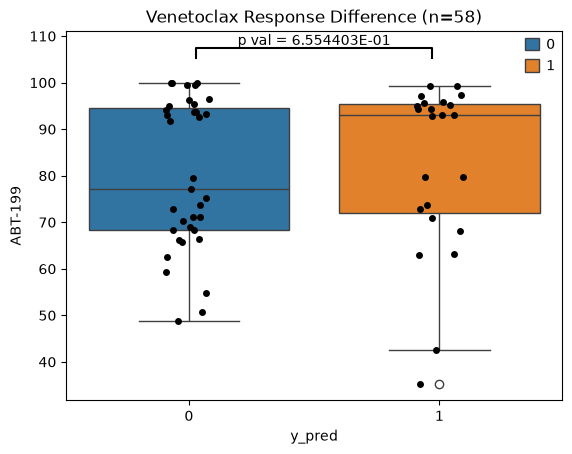

In [178]:
# analyze AUC differences of high confidence predictions
adata = mf_ad.copy()

adata = adata[high_conf_results.index]

adata.obs['y_pred'] = list(high_conf_results['y_pred'])
adata.obs['y_prob'] = list(high_conf_results['y_prob'])

fig, ax = plt.subplots(1)
plt.title(f'Venetoclax Response Difference (n={len(adata.obs)})')
sns.boxplot(adata.obs, y='ABT-199', x='y_pred', hue='y_pred')
sns.stripplot(adata.obs, y='ABT-199', x='y_pred',color='k')

test = ttest_ind(adata[adata.obs['y_pred'] == 1].obs['ABT-199'], adata[adata.obs['y_pred'] == 0].obs['ABT-199'])
annotation = (0, 1, f"p val = {test.pvalue:3E}")
starbars.draw_annotation([annotation])

2.0 0.03
2.0 0.03
2.0 0.03
2.0 0.03
2.0 0.03
2.0 0.03
2.0 0.03
2.0 0.03


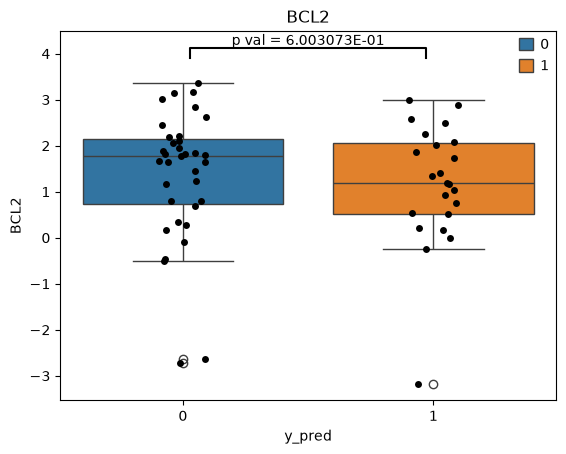

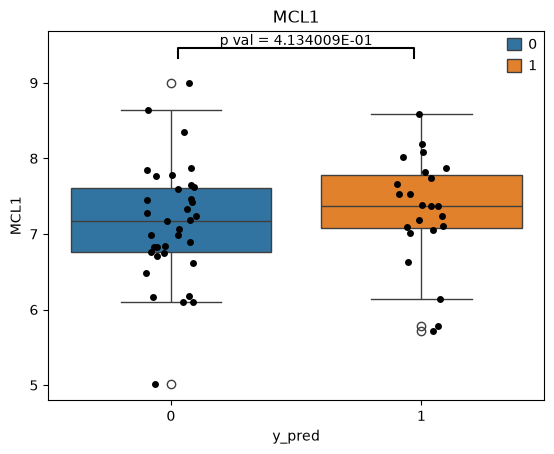

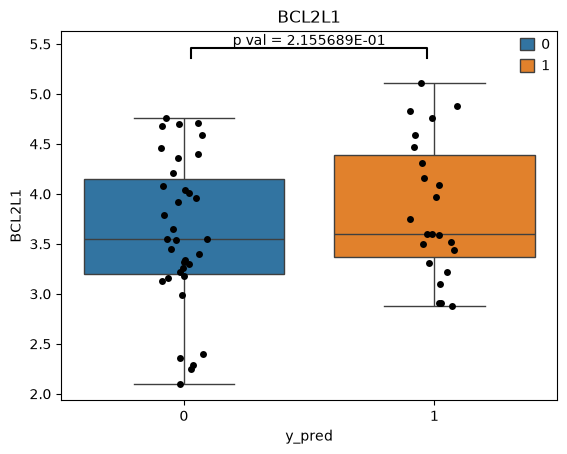

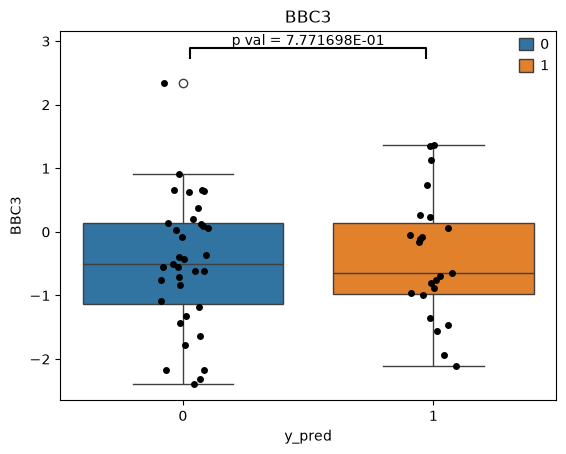

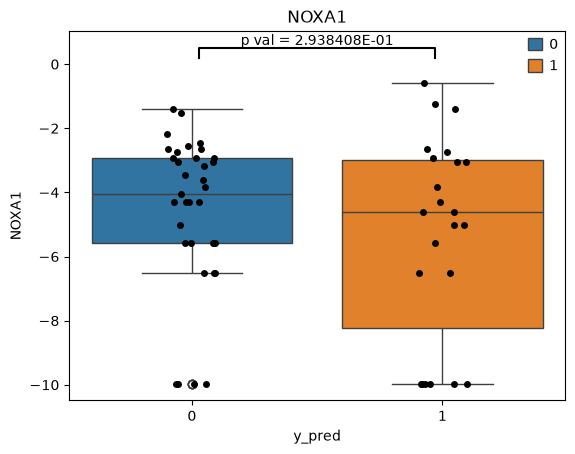

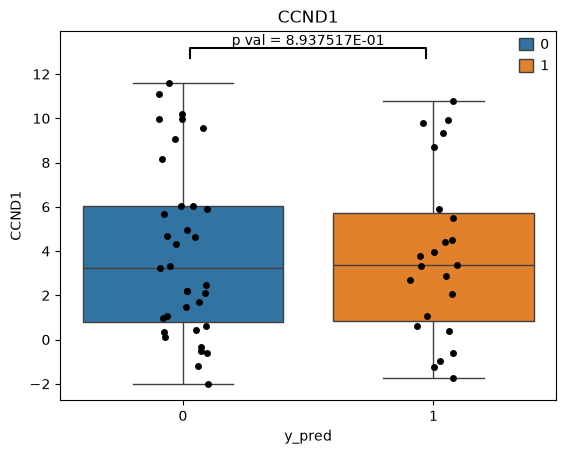

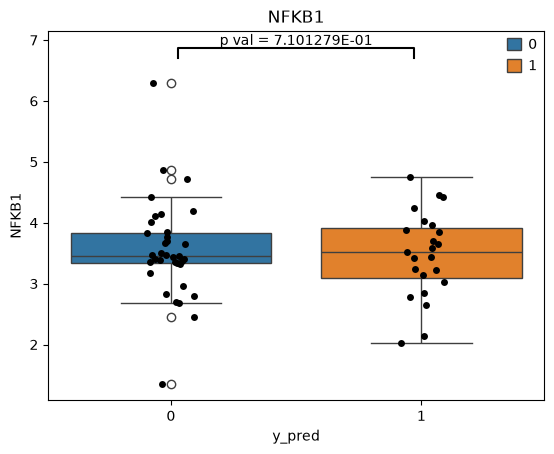

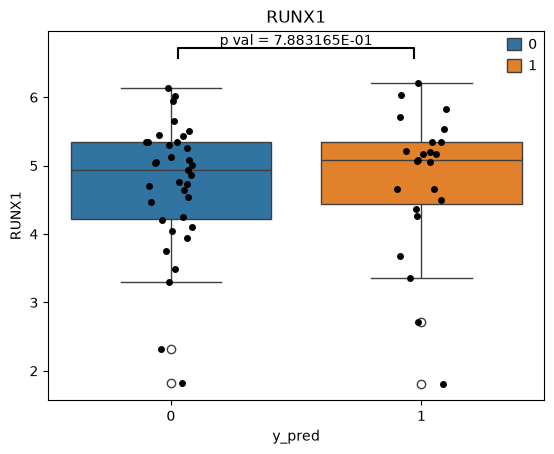

In [179]:
sensitive_ad = adata[adata.obs['y_pred'] == 1]
resistant_ad = adata[adata.obs['y_pred'] == 0]
# difference in mean expression of key genes
genes_of_interest = ["BCL2", "MCL1","BCL2L1", "BBC3", "NOXA1", "CCND1", 'NFKB1', "RUNX1"]

for gene in genes_of_interest:
    test =  ttest_ind(sensitive_ad.to_df()[gene], resistant_ad.to_df()[gene], alternative='two-sided')
    
    fig, ax = plt.subplots(1)
    expr = adata.to_df()
    expr['y_pred'] = adata.obs['y_pred']

    plt.title(gene)
    sns.boxplot(expr, y=gene, x='y_pred', hue='y_pred')
    sns.stripplot(expr, y=gene, x='y_pred',color='k')

    annotation = (0, 1, f"p val = {test.pvalue:3E}")
    starbars.draw_annotation([annotation])


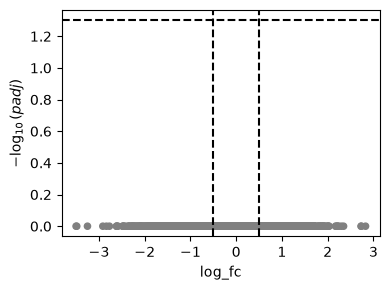

In [180]:
# limma for differential expression analysis
expr = adata.to_df()
design = np.column_stack([np.ones( len(adata.obs['y_pred']) ), np.array(adata.obs['y_pred']) ])

fit = pylimma.lm_fit(expr.transpose(), design)
fit = pylimma.contrasts_fit(fit, contrasts=np.array([[0], [1]]))
fit = pylimma.e_bayes(fit)

results_df = pylimma.top_table(fit,coef=0, key="fit",number=np.inf,sort_by="p")
results_df['padj'] = results_df["adj_p_value"]

dc.pl.volcano(data=results_df, x="log_fc", y="padj", top=30)
plt.show()


2026-09-17 19:11:38,481 [WARNING] Duplicated values found in preranked stats:
sample	ratio
log_fc         5.44%
ave_expr       6.73%
t              4.86%
p_value        4.97%
adj_p_value   99.99%
b              5.90%
padj          99.99%
The order of those genes will be arbitrary, which may produce unexpected results.


<Axes: title={'center': 'Predicted Sensitive vs. Resistant (High-Confidence)'}, xlabel='NES'>

<Figure size 640x480 with 0 Axes>

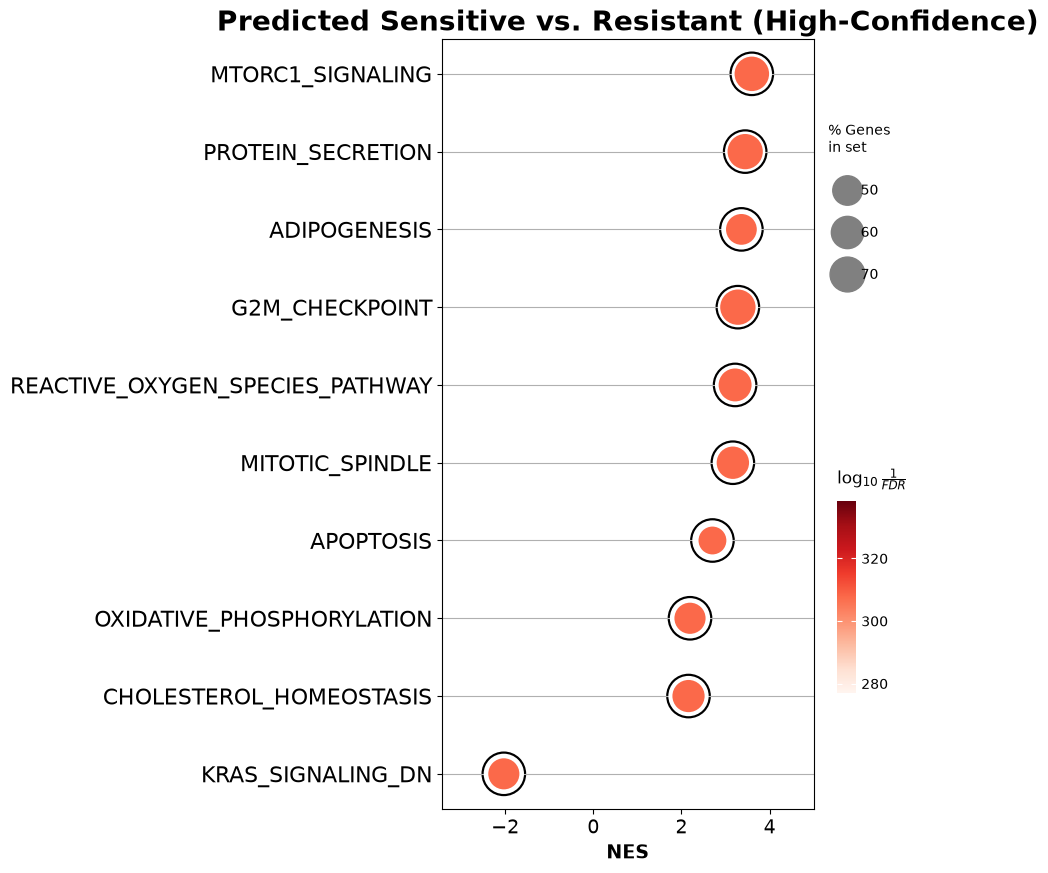

In [181]:
# GSEA
plt.clf()
gmt_dir = "../../data/GMT/"
hallmark_gmt = gmt_dir + "h.all.v2026.1.Hs.symbols.gmt"

results_df = results_df.sort_values(by="t")
pre_res = gp.prerank(rnk=results_df, gene_sets=[hallmark_gmt], threads=8, min_size=5, max_size=1000, outdir=None, seed=4)
pre_res.res2d = pre_res.res2d.sort_values(by="NES")
pre_res.res2d["Term"] = (
    pre_res.res2d["Term"]
    .str.replace("h.all.v2026.1.Hs.symbols.gmt__HALLMARK_", "", regex=False)
)


pre_res.res2d = pre_res.res2d.sort_values("FDR q-val").drop_duplicates(subset="Term")
pre_res.res2d = pre_res.res2d.sort_values(by="NES")



gp.dotplot(pre_res.res2d,column="FDR q-val",cmap="Reds", center=0, title='Predicted Sensitive vs. Resistant (High-Confidence)', size=5,figsize=(6, 10),cutoff=0.05,show_ring=True,)


<Axes: xlabel='y_pred', ylabel='t11_14'>

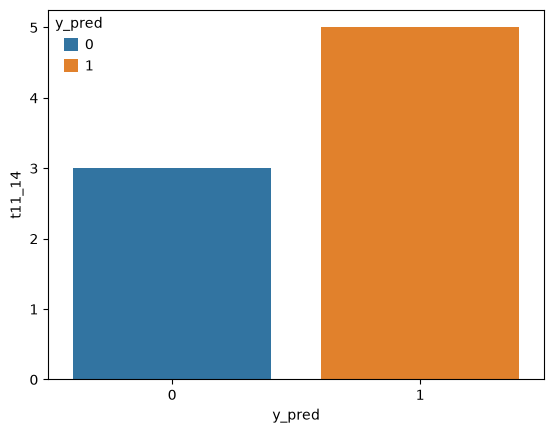